In [1]:
!pip -q install kagglehub scikit-learn

import os
from pathlib import Path
import kagglehub

dataset_path = Path(kagglehub.dataset_download("slothkong/10-monkey-species"))
print("Dataset downloaded to:", dataset_path)

# Inspect the downloaded folder structure
for p in list(dataset_path.rglob("*"))[:40]:
    print(p.relative_to(dataset_path))

Using Colab cache for faster access to the '10-monkey-species' dataset.
Dataset downloaded to: /kaggle/input/10-monkey-species
validation
training
monkey_labels.txt
validation/validation
training/training
training/training/n8
training/training/n6
training/training/n7
training/training/n1
training/training/n0
training/training/n2
training/training/n5
training/training/n4
training/training/n9
training/training/n3
training/training/n8/n8069.jpg
training/training/n8/n8045.jpg
training/training/n8/n8151.jpg
training/training/n8/n8047.jpg
training/training/n8/n8020.jpg
training/training/n8/n8052.jpg
training/training/n8/n8076.jpg
training/training/n8/n8066.jpg
training/training/n8/n8129.jpg
training/training/n8/n8049.jpg
training/training/n8/n8054.jpg
training/training/n8/n818.jpg
training/training/n8/n8140.jpg
training/training/n8/n8071.jpg
training/training/n8/n8116.jpg
training/training/n8/n8062.jpg
training/training/n8/n8056.jpg
training/training/n8/n8144.jpg
training/training/n8/n8149.j

In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Use the source folders named in the assignment appendix.
candidate_roots = [
    dataset_path / "training" / "training",
    dataset_path / "validation" / "validation",
]

image_paths = []
for root in candidate_roots:
    if root.exists():
        image_paths.extend(
            p for p in root.rglob("*")
            if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
        )

# If the dataset has a slightly different layout, search the downloaded folder.
if not image_paths:
    image_paths = [
        p for p in dataset_path.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ]

if not image_paths:
    raise FileNotFoundError(
        "No image files found. Check the printed folder structure and update candidate_roots."
    )

# The immediate parent folder is expected to be the class folder (e.g., n0, n1, ...).
df = pd.DataFrame({
    "path": [str(p) for p in image_paths],
    "class_name": [p.parent.name for p in image_paths],
}).drop_duplicates()

# Ignore files that are not inside class-specific folders.
df = df[df["class_name"].str.match(r"^n\d+$", na=False)].copy()

if df.empty:
    raise ValueError(
        "Could not identify class folders named n0, n1, ... "
        "Inspect the folder structure and adjust the class_name extraction."
    )

class_names = sorted(df["class_name"].unique())
class_to_id = {name: i for i, name in enumerate(class_names)}
id_to_class = {i: name for name, i in class_to_id.items()}
df["label"] = df["class_name"].map(class_to_id)

train_df, remaining_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df["label"]
)

val_df, test_df = train_test_split(
    remaining_df,
    test_size=0.50,
    random_state=42,
    stratify=remaining_df["label"]
)

print("Classes:", class_names)
print("Total images:", len(df))
print(f"Train: {len(train_df)} ({len(train_df)/len(df):.1%})")
print(f"Validation: {len(val_df)} ({len(val_df)/len(df):.1%})")
print(f"Test: {len(test_df)} ({len(test_df)/len(df):.1%})")

print("\nImages per class:")
display(df["class_name"].value_counts().sort_index().to_frame("count"))

Classes: ['n0', 'n1', 'n2', 'n3', 'n4', 'n5', 'n6', 'n7', 'n8', 'n9']
Total images: 1369
Train: 958 (70.0%)
Validation: 205 (15.0%)
Test: 206 (15.0%)

Images per class:


,count
class_name,
n0,131
n1,139
n2,137
n3,152
n4,131
n5,141
n6,132
n7,142
n8,133


In [3]:
import tensorflow as tf

SEED = 42
IMG_SIZE = (160, 160)
NUM_CLASSES = len(class_names)
AUTOTUNE = tf.data.AUTOTUNE

tf.keras.utils.set_random_seed(SEED)

def decode_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_image(image, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)
    return image, tf.cast(label, tf.int32)

def make_dataset(frame, batch_size, training=False):
    ds = tf.data.Dataset.from_tensor_slices((
        frame["path"].to_numpy(),
        frame["label"].to_numpy(dtype=np.int32)
    ))
    if training:
        ds = ds.shuffle(
            buffer_size=len(frame),
            seed=SEED,
            reshuffle_each_iteration=True
        )
    ds = ds.map(decode_image, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(batch_size).prefetch(AUTOTUNE)
    return ds

# Use these only for final evaluation / sample predictions.
# Do not use test_ds during experiment tuning.

In [4]:
from tensorflow import keras
from tensorflow.keras import layers

def build_model(dropout=0.2, augmentation=True):
    inputs = keras.Input(shape=(*IMG_SIZE, 3))

    x = inputs
    if augmentation:
        x = keras.Sequential([
            layers.RandomFlip("horizontal"),
            layers.RandomRotation(0.08),
            layers.RandomZoom(0.10),
        ], name="data_augmentation")(x)

    # MobileNetV2 expects pixels scaled to [-1, 1].
    x = layers.Rescaling(1.0 / 127.5, offset=-1)(x)

    base = keras.applications.MobileNetV2(
        input_shape=(*IMG_SIZE, 3),
        include_top=False,
        weights="imagenet"
    )
    base.trainable = False

    # training=False keeps pretrained BatchNorm layers in inference mode.
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

    model = keras.Model(inputs, outputs)
    return model, base

EXPERIMENTS = [
    {"name": "Exp 1", "lr_head": 1e-3, "lr_fine": 1e-4, "batch": 32,
     "head_epochs": 5, "fine_epochs": 3, "unfreeze": 0,  "dropout": 0.2, "aug": False},
    {"name": "Exp 2", "lr_head": 1e-3, "lr_fine": 1e-4, "batch": 32,
     "head_epochs": 5, "fine_epochs": 3, "unfreeze": 20, "dropout": 0.2, "aug": True},
    {"name": "Exp 3", "lr_head": 5e-4, "lr_fine": 5e-5, "batch": 32,
     "head_epochs": 5, "fine_epochs": 3, "unfreeze": 30, "dropout": 0.3, "aug": True},
    {"name": "Exp 4", "lr_head": 1e-3, "lr_fine": 1e-5, "batch": 16,
     "head_epochs": 5, "fine_epochs": 3, "unfreeze": 50, "dropout": 0.3, "aug": True},
    {"name": "Exp 5", "lr_head": 3e-4, "lr_fine": 3e-5, "batch": 32,
     "head_epochs": 5, "fine_epochs": 3, "unfreeze": 20, "dropout": 0.5, "aug": True},
    {"name": "Exp 6", "lr_head": 1e-3, "lr_fine": 1e-4, "batch": 64,
     "head_epochs": 5, "fine_epochs": 3, "unfreeze": 40, "dropout": 0.2, "aug": True},
]

In [5]:
import gc

experiment_results = []
experiment_histories = {}
best_val_accuracy = -1
best_model = None
best_config = None

for config in EXPERIMENTS:
    print("\n" + "=" * 70)
    print(config["name"], config)

    keras.backend.clear_session()
    gc.collect()
    tf.keras.utils.set_random_seed(SEED)

    train_ds = make_dataset(train_df, config["batch"], training=True)
    val_ds = make_dataset(val_df, config["batch"], training=False)

    model, base = build_model(
        dropout=config["dropout"],
        augmentation=config["aug"]
    )

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=config["lr_head"]),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    # Stage 1: feature extraction (base frozen)
    history_head = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=config["head_epochs"],
        verbose=1
    )

    # Stage 2: fine-tuning (unfreeze the requested number of top layers)
    if config["unfreeze"] > 0:
        base.trainable = True

        # Keep BatchNormalization layers frozen for stable fine-tuning.
        for layer in base.layers:
            layer.trainable = False

        for layer in base.layers[-config["unfreeze"]:]:
            if not isinstance(layer, layers.BatchNormalization):
                layer.trainable = True

        model.compile(
            optimizer=keras.optimizers.Adam(learning_rate=config["lr_fine"]),
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"]
        )

        history_fine = model.fit(
            train_ds,
            validation_data=val_ds,
            epochs=config["fine_epochs"],
            verbose=1
        )
    else:
        # No unfreezing is performed for this baseline experiment.
        history_fine = None

    head_best_val = max(history_head.history["val_accuracy"])
    fine_best_val = (
        max(history_fine.history["val_accuracy"])
        if history_fine is not None
        else head_best_val
    )
    final_train_acc = (
        history_fine.history["accuracy"][-1]
        if history_fine is not None
        else history_head.history["accuracy"][-1]
    )
    final_val_acc = (
        history_fine.history["val_accuracy"][-1]
        if history_fine is not None
        else history_head.history["val_accuracy"][-1]
    )

    experiment_results.append({
        **config,
        "head_best_val_accuracy": head_best_val,
        "fine_best_val_accuracy": fine_best_val,
        "final_train_accuracy": final_train_acc,
        "final_validation_accuracy": final_val_acc,
    })

    experiment_histories[config["name"]] = {
        "head": history_head.history,
        "fine": history_fine.history if history_fine is not None else None,
    }

    print(
        f"{config['name']} — best validation accuracy after fine-tuning: "
        f"{fine_best_val:.4f}"
    )

    if fine_best_val > best_val_accuracy:
        best_val_accuracy = fine_best_val
        best_model = model
        best_config = config.copy()

    # Don't clear the current best model from memory.
    if model is not best_model:
        del model, base
        gc.collect()

results_df = pd.DataFrame(experiment_results)
display(results_df)
print("\nBest configuration:", best_config)
print("Best validation accuracy:", round(best_val_accuracy, 4))

results_df.to_csv("experiment_results.csv", index=False)


Exp 1 {'name': 'Exp 1', 'lr_head': 0.001, 'lr_fine': 0.0001, 'batch': 32, 'head_epochs': 5, 'fine_epochs': 3, 'unfreeze': 0, 'dropout': 0.2, 'aug': False}
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/5
30/30 ━━━━━━━━━━━━━━━━━━━━ 46s 1s/step - accuracy: 0.5846 - loss: 1.3228 - val_accuracy: 0.9512 - val_loss: 0.4061
Epoch 2/5
30/30 ━━━━━━━━━━━━━━━━━━━━ 45s 1s/step - accuracy: 0.9572 - loss: 0.2938 - val_accuracy: 0.9707 - val_loss: 0.1763
Epoch 3/5
30/30 ━━━━━━━━━━━━━━━━━━━━ 41s 1s/step - accuracy: 0.9729 - loss: 0.1677 - val_accuracy: 0.9756 - val_loss: 0.1276
Epoch 4/5
30/30 ━━━━━━━━━━━━━━━━━━━━ 41s 1s/step - accuracy: 0.9843 - loss: 0.1090 - val_accuracy: 0.9756 - val_loss: 0.0995
Epoch 5/5
30/30 ━━━━━━━━━━━━━━━━━━━━ 36s 1s/step - accuracy: 0.9927 - loss: 0.0829 - val_accuracy: 0.9756 - val_loss: 0.0859
Exp 1 — best validation accuracy after fine-tuning: 0.9756

Exp 2 {'name': 'Exp 2', 'lr_head': 0.001, 'lr_fine': 0.0001, 'batch': 32, 'head_epochs': 5, 'fine_epochs': 3, 

,name,lr_head,lr_fine,batch,head_epochs,fine_epochs,unfreeze,dropout,aug,head_best_val_accuracy,fine_best_val_accuracy,final_train_accuracy,final_validation_accuracy
0,Exp 1,0.0010,0.00010,32,5,3,0,0.2,False,0.975610,0.975610,0.992693,0.975610
1,Exp 2,0.0010,0.00010,32,5,3,20,0.2,True,0.985366,0.985366,0.974948,0.985366
2,Exp 3,0.0005,0.00005,32,5,3,30,0.3,True,0.970732,0.980488,0.964509,0.975610
3,Exp 4,0.0010,0.00001,16,5,3,50,0.3,True,0.985366,0.980488,0.980167,0.980488
4,Exp 5,0.0003,0.00003,32,5,3,20,0.5,True,0.936585,0.970732,0.923800,0.970732
5,Exp 6,0.0010,0.00010,64,5,3,40,0.2,True,0.965854,0.980488,0.973904,0.980488



Best configuration: {'name': 'Exp 2', 'lr_head': 0.001, 'lr_fine': 0.0001, 'batch': 32, 'head_epochs': 5, 'fine_epochs': 3, 'unfreeze': 20, 'dropout': 0.2, 'aug': True}
Best validation accuracy: 0.9854


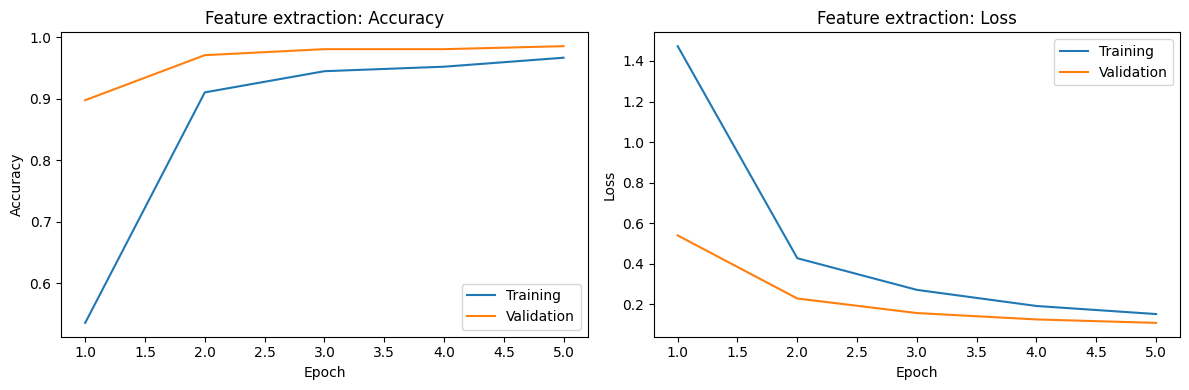

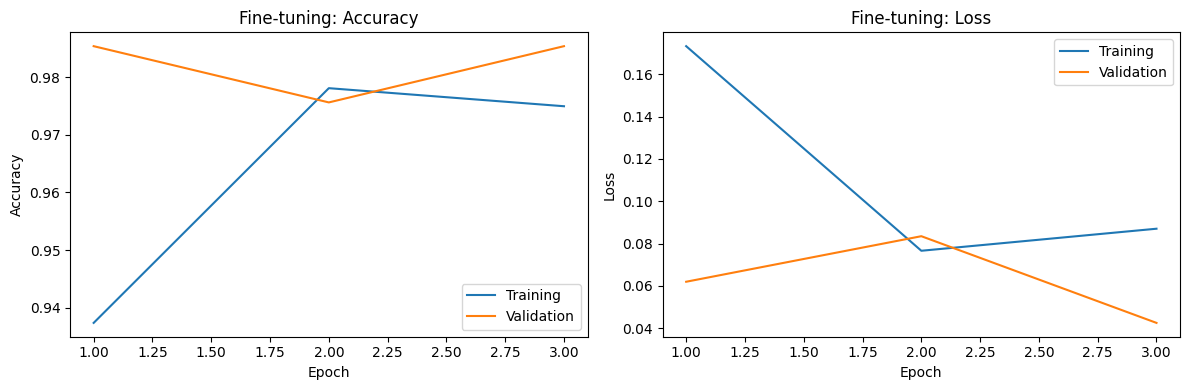

In [6]:
import matplotlib.pyplot as plt

best_history = experiment_histories[best_config["name"]]

def plot_history(history, stage_name):
    if history is None:
        print(f"{stage_name}: no fine-tuning was run for this experiment.")
        return

    epochs = range(1, len(history["accuracy"]) + 1)

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(epochs, history["accuracy"], label="Training")
    plt.plot(epochs, history["val_accuracy"], label="Validation")
    plt.title(f"{stage_name}: Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs, history["loss"], label="Training")
    plt.plot(epochs, history["val_loss"], label="Validation")
    plt.title(f"{stage_name}: Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()

    plt.tight_layout()
    plt.show()

plot_history(best_history["head"], "Feature extraction")
plot_history(best_history["fine"], "Fine-tuning")

In [7]:
test_ds = make_dataset(test_df, best_config["batch"], training=False)

test_loss, test_accuracy = best_model.evaluate(test_ds, verbose=1)
print(f"Final test accuracy: {test_accuracy:.4f}")
print(f"Final test loss: {test_loss:.4f}")

best_model.save("best_monkey_species_model.keras")

7/7 ━━━━━━━━━━━━━━━━━━━━ 8s 869ms/step - accuracy: 0.9757 - loss: 0.0548
Final test accuracy: 0.9757
Final test loss: 0.0548


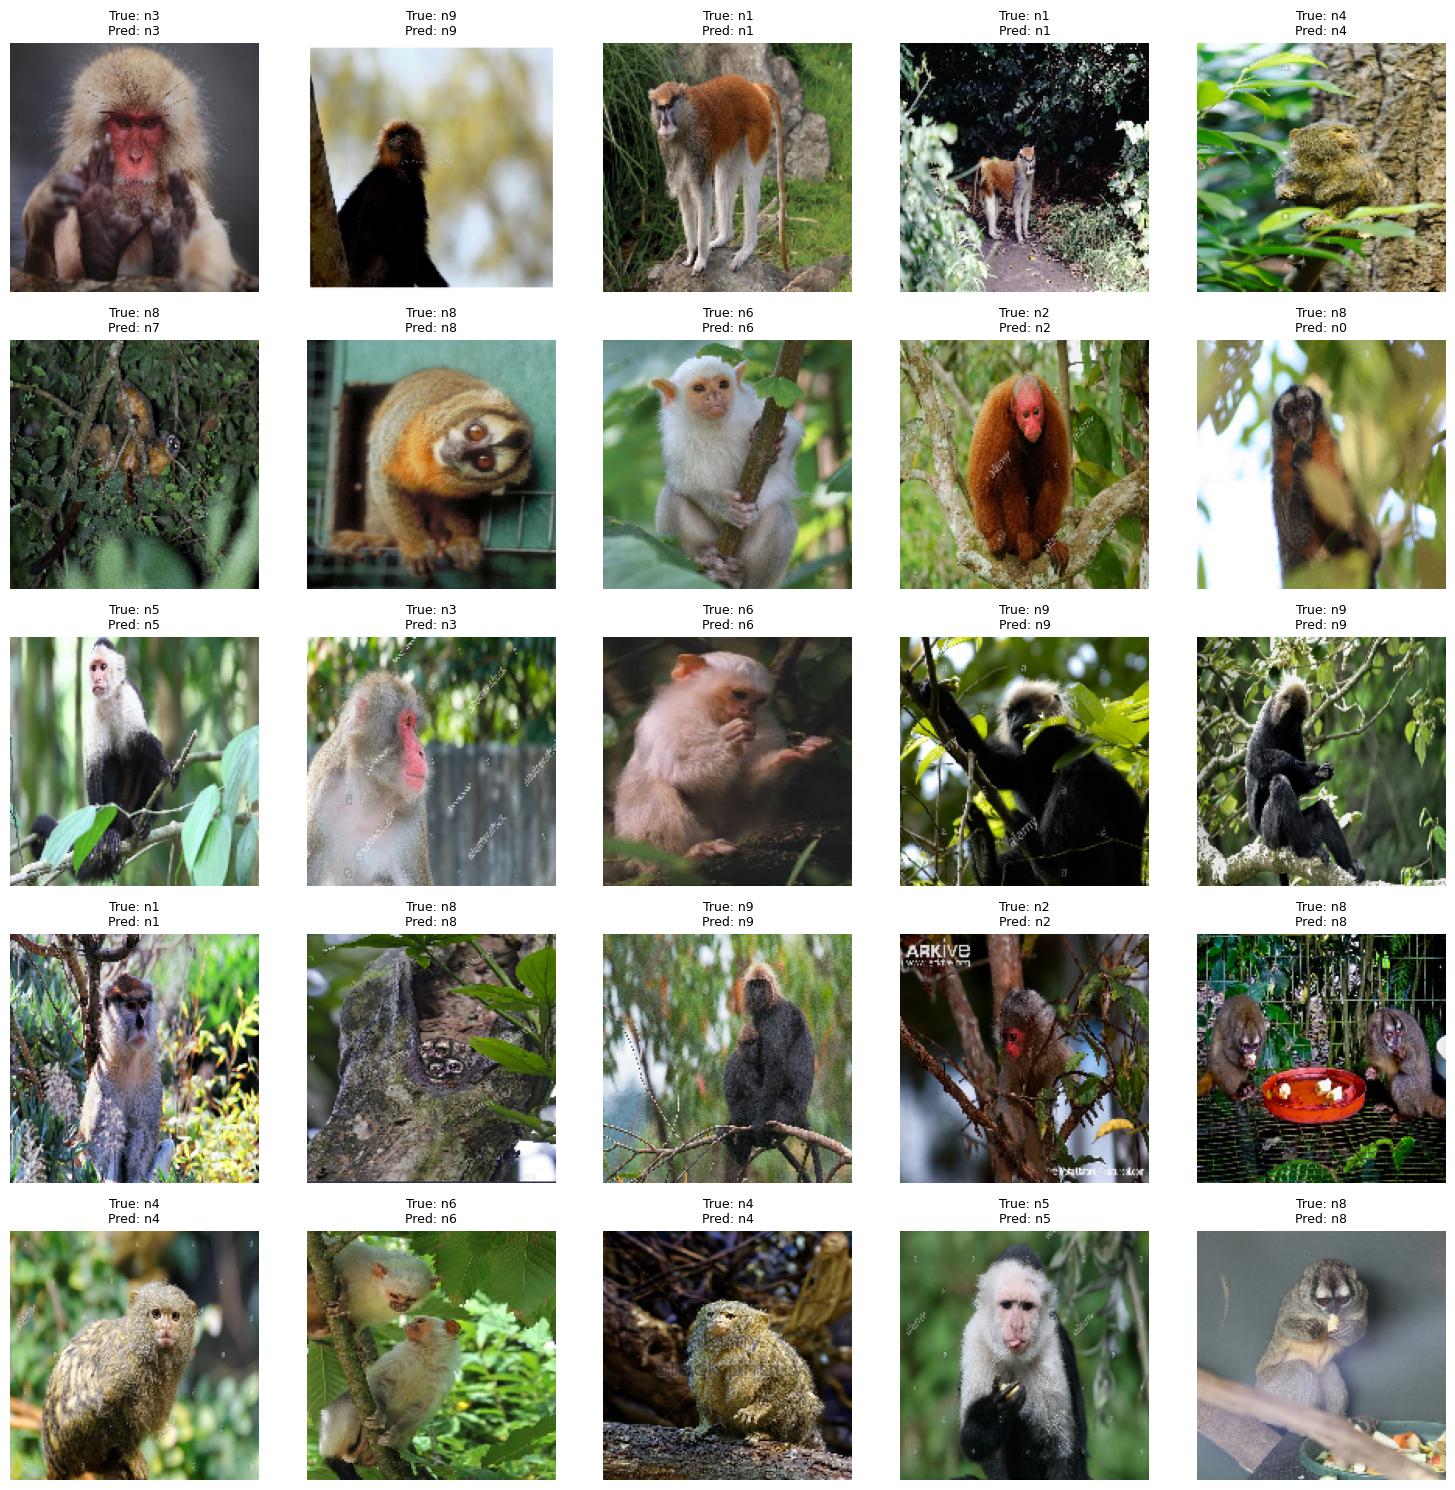

In [8]:
import matplotlib.pyplot as plt

sample_df = test_df.sample(
    n=min(25, len(test_df)),
    random_state=42
).reset_index(drop=True)

fig, axes = plt.subplots(5, 5, figsize=(15, 15))
axes = axes.flatten()

for i, row in sample_df.iterrows():
    image = tf.keras.utils.load_img(
        row["path"],
        target_size=IMG_SIZE
    )
    image_array = tf.keras.utils.img_to_array(image)

    probabilities = best_model.predict(
        np.expand_dims(image_array, axis=0),
        verbose=0
    )[0]

    predicted_id = int(np.argmax(probabilities))
    true_id = int(row["label"])

    axes[i].imshow(image)
    axes[i].set_title(
        f"True: {id_to_class[true_id]}\nPred: {id_to_class[predicted_id]}",
        fontsize=9
    )
    axes[i].axis("off")

for ax in axes[len(sample_df):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [9]:
results_df.to_csv("experiment_results.csv", index=False)
print("Saved experiment_results.csv")

Saved experiment_results.csv
